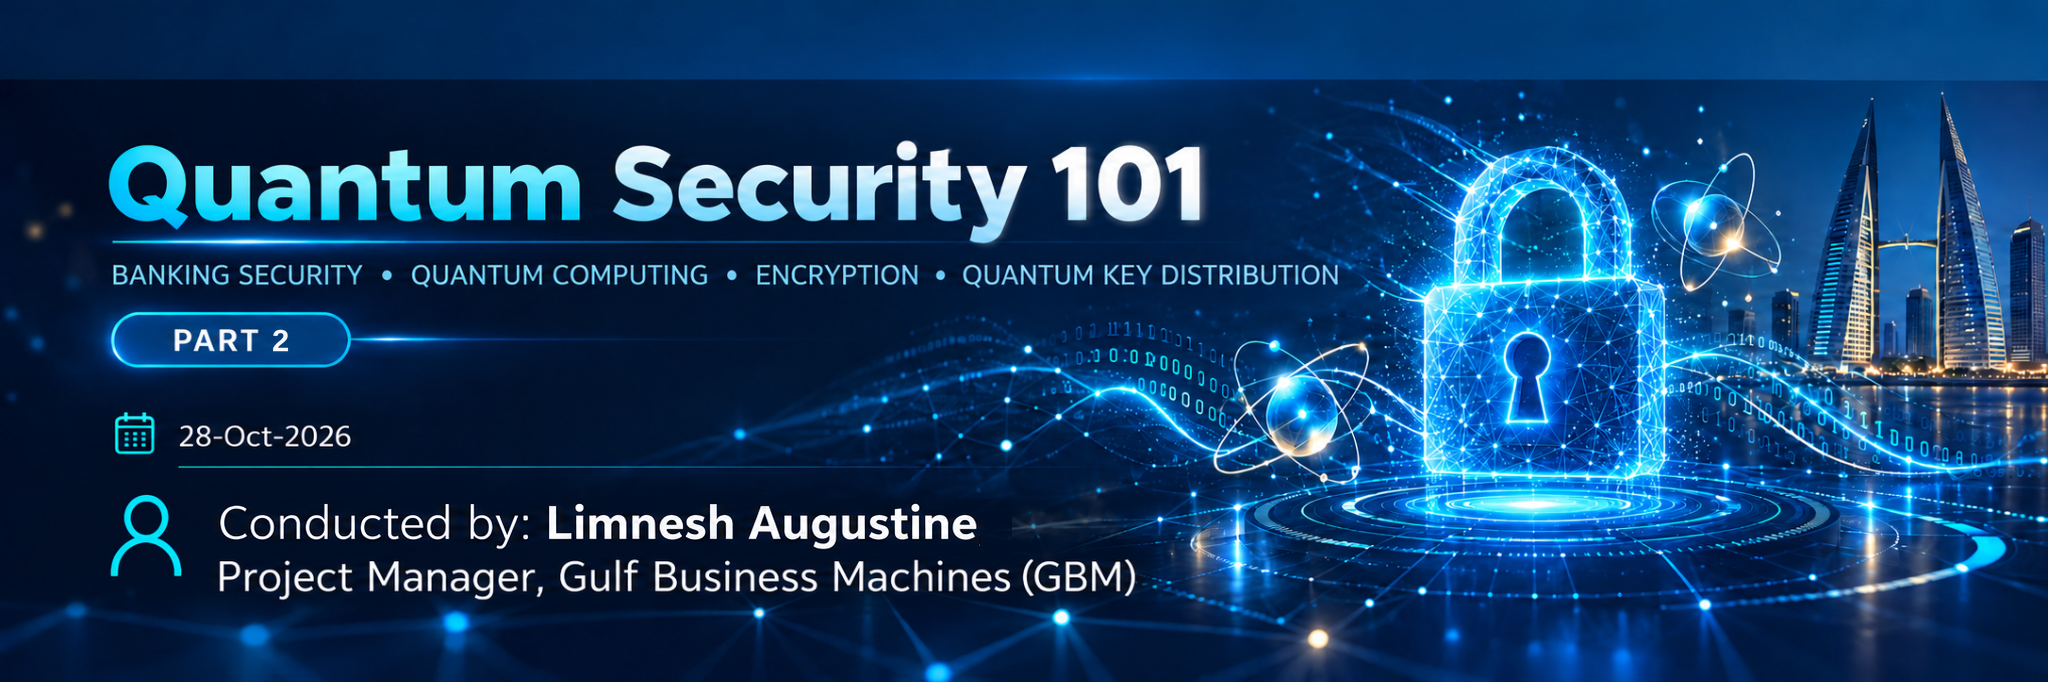
# PART 2 · From Bits to Qubits · The Quantum Threat
**BITEX 2026  /  BAHRAIN SAMPLE BANK (BSB)**

*Understand classical gates, meet the qubit, play with genuine Qiskit circuits, and return to Eve’s saved packet.*

> **Your mission:** Discover why a quantum computer is not just a faster laptop—and why classical DH/ECDH may be vulnerable in the future.

**🔵 LIVE** = follow along in the workshop &nbsp;&nbsp; **🟠 OPTIONAL** = explore afterward  
**⏱ 27 minutes live · Google Colab · Run cells from top to bottom**

| Chapter | Your experiment |
|:--|:--|
| **A · Classical logic** | Turn `25` and `3` into bits and build addition from gates |
| **B · Meet a qubit** | Six Bloch-sphere landmarks and one randomly prepared state |
| **C · Quantum lab** | Measure, rotate and entangle with actual Qiskit gates |
| **D · Return to BSB** | Simulate Shor-style DH recovery and decrypt the captured record |
| **Optional playground** | Interference, measurement bases, RSA and circuit-building challenges |

**How to use:** Read the short explanation, **predict what will happen**, then run the code. Change only values marked **✏️ YOUR TURN**. You do not need to understand every helper function to do the experiments.

---


---

## 🔵 LIVE · SETUP — Run this once in Colab

The next code cell loads the libraries used by all later experiments. If Qiskit is not installed, it installs the Python packages automatically.

**Run it once.** Subsequent cells reuse the same imports and helper functions. The main lab uses a **Qiskit statevector simulator**, not a real quantum processor.

> A few interactive dashboards are large code cells behind the scenes. You can simply use their buttons; the explanations remain in normal Colab **Text** cells.


In [1]:
# @title ⚙️ Setup — run once
# RUN FIRST — Colab setup, imports, shared presentation tools
# Run once; Colab may install Qiskit on a fresh runtime.
import sys, subprocess, io, base64, json, hmac, math, os
from hashlib import sha256
from fractions import Fraction
from math import gcd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
try:
    import qiskit, pylatexenc, ipywidgets
except ImportError:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','qiskit','pylatexenc','ipywidgets'])
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Pauli, partial_trace
from types import SimpleNamespace
from qiskit.visualization import plot_bloch_multivector
from qiskit.visualization.bloch import Bloch
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
import ipywidgets as widgets
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError: pass

from html import escape as html_escape

def show_metrics(title, entries, note='', orange=False):
    accents = ['#80caff','#fcd34d','#76f2c0','#d4b5ff']
    cards = ''.join(f'<div style="flex:1 1 190px;border:1px solid #365275;background:#19375c;border-radius:11px;padding:15px"><div style="font-size:13px;color:#d2e3fa">{html_escape(str(k))}</div><div style="font-size:26px;font-weight:800;color:{accents[i%4]};overflow-wrap:anywhere">{html_escape(str(v))}</div></div>' for i,(k,v) in enumerate(entries))
    display(HTML(f'<div style="background:{"#2d1d11" if orange else "#102746"};padding:19px;border-radius:14px;color:white;max-width:1120px;font:15px Arial;box-sizing:border-box"><div style="font-weight:bold;font-size:20px;color:white;margin-bottom:12px">{html_escape(title)}</div><div style="display:flex;flex-wrap:wrap;gap:10px">{cards}</div><div style="font-size:12px;color:#d0dfee;margin-top:12px">{html_escape(note)}</div></div>'))

print('Colab setup complete · Qiskit',qiskit.__version__)
# Colab files API, when present.
try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None


Colab setup complete · Qiskit 0.45.1


---

## 🔵 LIVE . Step 1 — A bit is an ordinary ON/OFF switch

A classical bit has **one definite value**, either `0` or `1`—like a switch that is OFF or ON. Computers represent numbers, files and banking records using sequences of these bits.

| Bit | Everyday analogy | Binary value |
|:--|:--|:--|
| **0** | Switch OFF | `0` |
| **1** | Switch ON | `1` |

Before we discuss qubits, let's encode two simple numbers: **25** and **3**. The bits below are the same kind of information a normal computer manipulates.

**✏️ Your turn:** change `first_number` and `second_number`. **Predict:** how many binary digits are needed to represent 25?


In [2]:
# LIVE — YOUR TURN: change these two numbers
first_number=25     # Try 12 or 19
second_number=3     # Try 7 or 5
assert isinstance(first_number,int) and isinstance(second_number,int)
assert min(first_number,second_number)>=0
bit_width=max(7,(first_number+second_number).bit_length())
first_bits=format(first_number,f'0{bit_width}b')
second_bits=format(second_number,f'0{bit_width}b')
show_metrics('Numbers become bits', [('Number A',str(first_number)+' → '+first_bits),('Number B',str(second_number)+' → '+second_bits)],'Each binary digit is a definite 0 or 1. The width grows automatically if you enter larger numbers.')

---

## 🔵 LIVE · Step 2 — Four building blocks: NOT, AND, OR and XOR

A **logic gate** is a tiny decision-maker: it receives one or two bits and gives a result. Physical computers use enormous networks of these simple operations.

| Gate | Everyday rule | Example |
|:--|:--|:--|
| **NOT** | Reverse 0 and 1 | `NOT(1) → 0` |
| **AND** | 1 only when **both** are 1 | `1 AND 0 → 0` |
| **OR** | 1 when **at least one** is 1 | `1 OR 0 → 1` |
| **XOR** | 1 when the inputs are **different** | `1 XOR 0 → 1` |

**Predict first:** What does `1 XOR 1` give? Check it in the next cell. You'll soon see why XOR is useful for adding binary numbers.

**✏️ Your turn:** change `bit_a` and `bit_b` before running.


In [3]:
# LIVE — Gate truth values, with editable input bits
# YOUR TURN: change bit_a and bit_b, then run.
bit_a,bit_b=1,0
def classical_gate(gate,a,b=0):
    if gate=='NOT':return 1-a
    if gate=='AND':return a & b
    if gate=='OR':return a | b
    if gate=='XOR':return a ^ b
    raise ValueError('Unknown gate')
for gate in ['NOT','AND','OR','XOR']:
    val=classical_gate(gate,bit_a,bit_b)
    print(f'{gate:>3}: input {bit_a}' + ('' if gate=='NOT' else f', {bit_b}') + f'  →  output {val}')

NOT: input 1  →  output 0
AND: input 1, 0  →  output 0
 OR: input 1, 0  →  output 1
XOR: input 1, 0  →  output 1


---

## 🔵 LIVE · Step 3 — Build a circuit that adds two numbers

How does a computer calculate **25 + 3** using only gates? It processes one binary column at a time, from right to left.

A **full adder** uses **two XOR**, **two AND**, and **one OR** operation. It has three inputs—bit A, bit B and a *carry* from the previous column—and two outputs: the sum bit and the carry to the next column.

**Start with bit 0:** `1 + 1 = 10` in binary. Write down `0` and carry `1`.

The next cell **prepares** the gate values for every column. The following cell will display just **one clear five-gate example**, rather than seven crowded circuits.


In [4]:
# LIVE — Prepare seven-bit ripple-carry addition
carry=0
adder_steps=[]
for i in range(bit_width):
    a=(first_number>>i)&1
    b=(second_number>>i)&1
    p=a^b                      # XOR gate 1
    sum_bit=p^carry            # XOR gate 2
    carry_out=(a&b)|(p&carry) # AND, AND, OR
    adder_steps.append((i,a,b,carry,sum_bit,carry_out))
    carry=carry_out
sum_bits=''.join(str(step[4]) for step in reversed(adder_steps))
calculated_sum=int(sum_bits,2)
assert calculated_sum==first_number+second_number
print('Adder built from 2 XOR + 2 AND + 1 OR per column')
print('Total basic gate instances:',5*bit_width)

Adder built from 2 XOR + 2 AND + 1 OR per column
Total basic gate instances: 35


---

## 🔵 LIVE · Step 4 — Look inside one full adder

The visual below isolates **one binary column** so we can see the actual XOR, AND and OR gate symbols without tangled wiring.

**✏️ Your turn:** set `selected_bit = 0`, then try `1` and `2`. At each step, ask the group:

- What are the two input bits?
- Did a carry arrive from the previous column?
- What sum bit will we write, and what carry will move forward?

The same five gate rules are reused for every column. You do **not** need to memorize the entire wiring diagram.


In [5]:
# LIVE — Read ONE full-adder column (avoids a crowded wiring diagram)
# YOUR TURN — Change selected_bit to 1, 2, etc.
selected_bit=0
assert 0<=selected_bit<bit_width
i,a,b,carry_in,sum_bit,carry_out=adder_steps[selected_bit]
propagate=a^b
generate=a&b
carry_and=propagate&carry_in
show_metrics(f'Full adder · bit {selected_bit}', [('Inputs',f'A={a} · B={b} · Carry in={carry_in}'),('XOR → XOR',f'{propagate} XOR {carry_in} = {sum_bit}'),('AND / AND / OR',f'{generate} OR {carry_and} = {carry_out}'),('Result',f'Write {sum_bit} · Carry {carry_out}')], 'Real arithmetic from basic gate operations; no fake carry wires.')
# One readable FIVE-GATE circuit — two gates for SUM, three for CARRY.
# Gate shapes are drawn separately so the audience can follow them.
def logic_gate_svg(kind, color):
    if kind=='AND':
        outline='<path d="M8 7 H33 Q60 7 60 28 Q60 49 33 49 H8 Z"/>'
    else:
        outline='<path d="M9 7 Q37 7 63 28 Q37 49 9 49 Q23 28 9 7 Z"/>'
        if kind=='XOR':outline+='<path d="M1 7 Q15 28 1 49" fill="none"/>'
    return (f'<svg width="83" height="59" viewBox="0 0 83 59" xmlns="http://www.w3.org/2000/svg">'
       f'<g fill="white" stroke="{color}" stroke-width="2.5">{outline}</g>'
       f'<text x="34" y="32" font-family="Arial" font-size="12" text-anchor="middle" fill="{color}" font-weight="bold">{kind}</text></svg>')

def gate_chunk(kind, left, answer, color):
    return (f'<span style="display:inline-flex;align-items:center;gap:7px;padding:5px 7px;border:1px solid #d7e5f4;border-radius:9px;background:#f9fcff">'
            f'<span style="color:#253c57;font-size:13px;font-weight:bold">{left}</span>{logic_gate_svg(kind,color)}'
            f'<span style="color:{color};font-size:15px;font-weight:800">{answer}</span></span>')

sum_path=(gate_chunk('XOR',f'{a} , {b}',propagate,'#2563eb')+'<span style="color:#64748b;font-size:24px">→</span>'+
          gate_chunk('XOR',f'{propagate} , {carry_in}',sum_bit,'#2563eb'))
carry_path=(gate_chunk('AND',f'{a} , {b}',generate,'#7c3aed')+'<span style="color:#64748b;font-size:20px">+</span>'+
            gate_chunk('AND',f'{propagate} , {carry_in}',carry_and,'#7c3aed')+'<span style="color:#64748b;font-size:24px">→</span>'+
            gate_chunk('OR',f'{generate} , {carry_and}',carry_out,'#ea580c'))
display(HTML(f"""<div style="background:#eef5ff;border-radius:14px;padding:18px;max-width:1100px;font-family:Arial;color:#173452">
  <div style="font-size:20px;font-weight:800;margin-bottom:7px">Inside one full adder · Bit {selected_bit}</div>
  <div style="font-size:13px;color:#566a86;margin-bottom:14px">Follow the two independent paths. Five real logic gate symbols; no overlapping wires.</div>
  <div style="background:white;border-radius:10px;padding:12px;margin-bottom:9px">
    <b style="color:#2563eb">SUM bit</b><div style="display:flex;gap:9px;align-items:center;flex-wrap:wrap;margin-top:7px">{sum_path}</div></div>
  <div style="background:white;border-radius:10px;padding:12px">
    <b style="color:#9a3412">CARRY bit</b><div style="display:flex;gap:9px;align-items:center;flex-wrap:wrap;margin-top:7px">{carry_path}</div></div>
</div>"""))


---

## 🔵 LIVE · Step 5 — Read the result as an ordinary number

Now all seven binary positions have been processed. The individual output bits join to form a new binary number—which we can read as an ordinary decimal number.

**Prediction:** `25 + 3` should give `28`. Does the binary output agree?

**Big idea:** the circuit never needed to know what “25” *means*. It just followed gate rules on `0` and `1`.


In [ ]:
# LIVE — Final arithmetic result
show_metrics('Classical circuit · completed', [('A',f'{first_number} → {first_bits}'),('B',f'{second_number} → {second_bits}'),('Sum (binary)',sum_bits),('Sum (decimal)',calculated_sum)],'The circuit processes from the rightmost (least significant) bit toward the left.')

---

## 🟠 OPTIONAL · A · Extra — Multiplication uses repeated shifting and addition

Why stop at addition? For ordinary binary multiplication, a computer can shift a number left and add the partial results.

**✏️ Your turn:** change `first_number` and `second_number`, then verify that the program gives their product. This is an optional behind-the-scenes exercise, not needed before we introduce qubits.


In [ ]:
# ORANGE OPTIONAL — Multiply using shifts and add operations
product=0
for i in range(second_number.bit_length()):
    if second_number & (1<<i): product+=first_number<<i
assert product==first_number*second_number
print(first_number,'×',second_number,'=',product,'| binary:',format(product,'b'))

---

## 🔵 LIVE · Step 6 — Meet a qubit: more than an ON/OFF switch

A classical bit is **definitely 0 or 1**. A pure **qubit** can be represented as an arrow pointing **anywhere on a Bloch sphere**. The arrow depicts a quantum *state*, not a tiny physical ball spinning in space.

| Axis | One end | Opposite end |
|:--|:--|:--|
| **Z** | $\lvert0\rangle$ (north) | $\lvert1\rangle$ (south) |
| **Y** | $\lvert+i\rangle$ | $\lvert-i\rangle$ |
| **X** | $\lvert+\rangle$ | $\lvert-\rangle$ |

These are **six useful landmarks**, not all possible states. Four are superpositions in the 0/1 measurement basis; the two poles are definite in that basis.

The state can be written as:

$$
\lvert\psi\rangle = \alpha\lvert0\rangle + \beta\lvert1\rangle, \qquad |\alpha|^2 + |\beta|^2 = 1
$$

The numbers $|\alpha|^2$ and $|\beta|^2$ are the chances of measuring **0** or **1**.

> **Important:** a superposition is *not* two classical bits you can read at once. One measurement produces one ordinary result.

The next code cell prepares the six states using **Qiskit**, plus one fresh, randomly oriented qubit.


In [6]:
# LIVE — Create reference states (Qiskit) and a uniformly random pure qubit
rt2=np.sqrt(2)
one=Statevector([0,1]); zero=Statevector([1,0])
plus_i=Statevector(np.array([1,1j])/rt2)
minus_i=Statevector(np.array([1,-1j])/rt2)
plus=Statevector(np.array([1,1])/rt2)
minus=Statevector(np.array([1,-1])/rt2)
qubit_state_order=['1','0','+i','-i','+','-']
qubit_states={'1':one,'0':zero,'+i':plus_i,'-i':minus_i,'+':plus,'-':minus}
states_six=[(f'|{name}⟩',qubit_states[name]) for name in qubit_state_order]
states=[qubit_states[name] for name in qubit_state_order]
before_probs=zero.probabilities_dict()
probabilities=plus.probabilities_dict()
p0=100*probabilities.get('0',0);p1=100*probabilities.get('1',0)

def make_random_qubit():
    rng=np.random.default_rng()
    z=rng.uniform(-1,1)
    theta=np.arccos(z)
    phi=rng.uniform(0,2*np.pi)
    state=Statevector(np.array([np.cos(theta/2),np.exp(1j*phi)*np.sin(theta/2)],dtype=complex))
    return state,theta,phi

def sphere_png(state,size=2.1):
    fig=plot_bloch_multivector(state,figsize=(size,size))
    buff=io.BytesIO()
    fig.savefig(buff,format='png',dpi=110,bbox_inches='tight',pad_inches=.02,facecolor='white')
    plt.close(fig)
    return base64.b64encode(buff.getvalue()).decode('ascii')

random_qubit_state,random_theta,random_phi=make_random_qubit()
random_probabilities=random_qubit_state.probabilities_dict()
print('Six reference states prepared + one random qubit.')

Six reference states prepared + one random qubit.


---

## 🔵 LIVE · Step 7 — Six familiar states—and one surprise

Look at the six small Bloch spheres on the left, always in the same order: **`1, 0, +i, -i, +, -`**. The seventh sphere on the right is a **new random qubit**.

Notice that the four equator states all have **50% chance of 0 and 50% chance of 1** when measured in the 0/1 basis—yet their arrows point in different directions. This difference is **relative phase**, and it matters when gates are applied later.

**🎲 Audience activity:** click **Randomize Qubit** repeatedly. Watch the arrow change and the 0/1 percentages update. Why do some random states look almost certain, while others are close to 50/50?


In [7]:
# LIVE — Six familiar states (same labels throughout the notebook)
columns=[('Z AXIS',['1','0']),('Y AXIS',['+i','-i']),('X AXIS',['+','-'])]
reference_html=''
for axis,names in columns:
    tiles=''
    for name in names:
        s=qubit_states[name]
        q0,q1=[100*float(v) for v in s.probabilities()]
        pic=sphere_png(s,2.1)
        kind='SUPERPOSITION' if q0>0.001 and q1>0.001 else 'DEFINITE IN 0/1 BASIS'
        tiles+=f"""<div style="background:white;color:#173451;border-radius:11px;text-align:center;padding:8px;margin:5px 0;border:1px solid #cfdef1">
          <div style="font-size:21px;font-weight:800">|{name}⟩</div>
          <img src="data:image/png;base64,{pic}" style="width:100%;height:107px;object-fit:contain;display:block"/>
          <div style="font-size:10px;font-weight:bold;color:#677d97">{kind}</div>
          <div style="display:flex;justify-content:space-between;font-weight:bold;font-size:12px"><span style="color:#0369a1">0: {q0:.0f}%</span><span style="color:#7c3aed">1: {q1:.0f}%</span></div></div>"""
    reference_html+=f'<div style="min-width:0"><div style="font-size:13px;font-weight:bold;text-align:center;color:#bde1ff">{axis}</div>{tiles}</div>'

def build_qubit_dashboard():
    global random_pic,r0,r1
    random_pic=sphere_png(random_qubit_state,3.2)
    r0,r1=[100*float(x) for x in random_qubit_state.probabilities()]
    return f"""<div style="background:#0c2342;color:white;border-radius:15px;padding:19px;font:14px Arial;box-sizing:border-box;width:100%">
      <div style="font-size:26px;font-weight:800;color:white;margin-bottom:4px">Meet a Qubit</div>
      <div style="color:#bfd8f8;margin-bottom:15px">Six reference points. A qubit can also point anywhere on the Bloch sphere.</div>
      <div style="display:flex;flex-wrap:wrap;gap:15px">
      <div style="flex:2 1 510px;min-width:0;display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:8px">{reference_html}</div>
      <div style="flex:1 1 260px;min-width:0;border:2px solid #2dd4bf;background:#113450;border-radius:12px;padding:13px;text-align:center;box-sizing:border-box">
      <div style="color:#5eead4;font-weight:800;font-size:18px">NEW RANDOM QUBIT · |ψ⟩</div>
      <img src="data:image/png;base64,{random_pic}" style="width:100%;height:230px;object-fit:contain;display:block"/>
      <div style="display:flex;gap:8px"><div style="flex:1;padding:9px;background:#dff5ff;color:#075985;border-radius:9px"><b style="font-size:26px">{r0:.1f}%</b><br/>Get 0</div>
      <div style="flex:1;padding:9px;background:#ede9fe;color:#6d28d9;border-radius:9px"><b style="font-size:26px">{r1:.1f}%</b><br/>Get 1</div></div>
      <div style="color:#bfd8f8;font-size:12px;margin-top:11px">These are chances, not two readable bits.</div></div></div></div>"""

qubit_dashboard=widgets.HTML(value=build_qubit_dashboard(),layout=widgets.Layout(width='100%'))
random_button=widgets.Button(description='🎲 Randomize Qubit',button_style='info',layout=widgets.Layout(width='220px',height='45px'))
def randomize_qubit(_):
    global random_qubit_state,random_theta,random_phi,random_probabilities
    random_qubit_state,random_theta,random_phi=make_random_qubit()
    random_probabilities=random_qubit_state.probabilities_dict()
    qubit_dashboard.value=build_qubit_dashboard()
random_button.on_click(randomize_qubit)
display(widgets.VBox([qubit_dashboard,random_button],layout=widgets.Layout(width='100%',gap='9px')))

---

## 🔵 LIVE · Step 8 — Prepare a qubit before measuring it

Now imagine Bob has received a qubit. Before clicking *Measure*, he can inspect its **predicted probabilities**. But he cannot know the single random result in advance.

The next cell creates a new random state without measuring it. Alternatively, choose one of the six familiar states or **`SAME`** to use the random state from the previous section.

**✏️ Your turn:** choose `measurement_choice = 'RANDOM'` first. Later test `0`, `1` and `+`.


In [8]:
# LIVE — Prepare a state; no measurement yet
# YOUR TURN: 'RANDOM', 'SAME', '1', '0', '+i', '-i', '+', '-'
measurement_choice='RANDOM'
def prepare_measurement(choice):
    if choice=='RANDOM':return (*make_random_qubit(),'New random |ψ⟩')
    if choice=='SAME':return random_qubit_state,random_theta,random_phi,'Random qubit from Section 4'
    if choice in qubit_states:
        s=qubit_states[choice]
        th=2*np.arccos(np.clip(abs(s.data[0]),0,1))
        ph=(np.angle(s.data[1])-np.angle(s.data[0]))%(2*np.pi)
        return s,th,ph,f'|{choice}⟩'
    raise ValueError('Choose RANDOM, SAME, 1, 0, +i, -i, + or -')
selected_state,measurement_theta,measurement_phi,prepared_label=prepare_measurement(measurement_choice)
def update_measurement_probabilities():
    global measurement_probs,prob_0,prob_1,pre_png
    measurement_probs=selected_state.probabilities_dict()
    prob_0=100*float(measurement_probs.get('0',0))
    prob_1=100*float(measurement_probs.get('1',0))
    pre_png=sphere_png(selected_state,3)
update_measurement_probabilities()
result,collapsed,post_png=None,None,None
print('Prepared:',prepared_label,'— waiting for measurement.')

Prepared: New random |ψ⟩ — waiting for measurement.


---

## 🔵 LIVE · Step 9 — One click gives one measurement result

The **left sphere** shows the state *before measurement*. Its two percentages are the chances of seeing 0 or 1. Click **Measure Qubit** and the **right sphere** shows what Qiskit returned.

- **Randomize** prepares a fresh qubit.
- **Measure** produces **one** result: `0` or `1`.
- After measurement, our simulator displays a corresponding 0/1-basis state.

Try the same state several times by preparing new copies. You won't see “0.5” coming out of a single measurement: only ordinary bits.

**Physical distinction:** many photon detectors absorb the photon, but other quantum hardware can measure a qubit without destroying the physical system. Measurement does not universally mean the particle disappears.


In [9]:
# LIVE — Visual measurement button, with before/after spheres
def measurement_dashboard():
    after=(f"""<div style="background:white;color:#173452;border-radius:11px;padding:12px;text-align:center">
       <b style="font-size:17px">AFTER MEASUREMENT</b><img src="data:image/png;base64,{post_png}" style="width:100%;height:195px;object-fit:contain"/>
       <div style="background:#dcfce7;color:#166534;font-size:22px;padding:9px;border-radius:8px;font-weight:800">Measured |{result}⟩</div></div>""" if result is not None else
       """<div style="background:#193859;border:2px dashed #6884aa;border-radius:11px;min-height:283px;display:flex;flex-direction:column;justify-content:center;text-align:center;color:white"><div style="font-size:54px">?</div><b>NOT MEASURED YET</b><div style="margin:8px;color:#bcd6f4">Click Measure Qubit</div></div>""")
    return f"""<div style="background:#0c2342;color:white;border-radius:15px;padding:20px;font:14px Arial;box-sizing:border-box;width:100%">
       <h2 style="color:white;margin:0 0 6px">Quantum Measurement</h2><div style="color:#bfdaff;margin-bottom:13px">Prepare → Measure → Get exactly one result.</div>
       <div style="display:flex;gap:13px;flex-wrap:wrap"><div style="flex:1 1 270px;min-width:0;background:white;color:#173452;border-radius:11px;padding:12px;text-align:center">
         <b style="font-size:17px">BEFORE MEASUREMENT</b><div style="color:#56718d">{html_escape(prepared_label)}</div>
         <img src="data:image/png;base64,{pre_png}" style="width:100%;height:195px;object-fit:contain"/>
         <div style="display:flex;gap:7px"><div style="flex:1;background:#dff5ff;color:#075985;border-radius:7px;padding:9px"><b style="font-size:23px">{prob_0:.1f}%</b><br/>Get 0</div>
         <div style="flex:1;background:#ede9fe;color:#6d28d9;border-radius:7px;padding:9px"><b style="font-size:23px">{prob_1:.1f}%</b><br/>Get 1</div></div></div>
         <div style="flex:1 1 270px;min-width:0">{after}</div></div></div>"""
measurement_view=widgets.HTML(value=measurement_dashboard(),layout=widgets.Layout(width='100%'))
randomize_button=widgets.Button(description='🎲 Randomize Qubit',button_style='info',layout=widgets.Layout(width='210px',height='44px'))
measure_button=widgets.Button(description='📏 Measure Qubit',button_style='success',layout=widgets.Layout(width='210px',height='44px'))
def on_randomize_clicked(_):
    global selected_state,measurement_theta,measurement_phi,prepared_label,measurement_choice,result,collapsed,post_png
    measurement_choice='RANDOM'
    selected_state,measurement_theta,measurement_phi,prepared_label=prepare_measurement('RANDOM')
    update_measurement_probabilities()
    result,collapsed,post_png=None,None,None
    measure_button.disabled=False
    measurement_view.value=measurement_dashboard()
def on_measure_clicked(_):
    global result,collapsed,post_png
    if result is not None:return
    result,collapsed=selected_state.measure()
    post_png=sphere_png(collapsed,3)
    measure_button.disabled=True
    measurement_view.value=measurement_dashboard()
randomize_button.on_click(on_randomize_clicked)
measure_button.on_click(on_measure_clicked)
display(widgets.VBox([measurement_view,widgets.HBox([randomize_button,measure_button])],layout=widgets.Layout(width='100%',gap='8px')))

---

## 🔵 LIVE · Step 10 — A quantum gate changes the state

A quantum gate acts on the *state* of a qubit. Some gates change its chances of yielding 0/1; others mainly change **phase**, which the Bloch sphere shows even when the percentages remain the same.

| Gate | Easy way to remember it | Try this input |
|:--|:--|:--|
| **X** | Flip $\lvert0\rangle$ to $\lvert1\rangle$ | `0` |
| **H** | Make an equal superposition from 0 | `0` |
| **Z** | Change the relative sign (phase) | `+` |
| **S / T** | Rotate phase by 90° / 45° | `+` |
| **RX / RY / RZ** | Rotate the Bloch arrow by an angle | Random |

We introduce **H here**, not in “Meet a Qubit,” so the story is **state → measurement → gates**.

The next cell prepares the genuine Qiskit gate renderer. The following one supplies the interactive controls.


In [10]:
# LIVE — Prepare Qiskit gate renderer and display helpers
# Shared image renderer; the two-qubit cell below reuses it.
def gate_sphere_png(state):
    n = state.num_qubits
    size = (3.6, 3.3) if n == 1 else (6.4, 3.2)
    fig = plot_bloch_multivector(state, figsize=size)
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=100,
                bbox_inches='tight', pad_inches=.02,
                facecolor='white')
    plt.close(fig)
    return base64.b64encode(buffer.getvalue()).decode('ascii')

# An output might be equal to a named state except for global phase.
def single_state_name(state):
    for name in ['1', '0', '+i', '-i', '+', '-']:
        ref = qubit_states[name]
        if abs(np.vdot(ref.data, state.data))**2 > 1 - 1e-9:
            return f'|{name}⟩'
    return '|ψ⟩'

def single_card(title, state, color, subtitle=""):
    """Reusable single-qubit display card."""
    p0, p1 = (100 * float(v) for v in state.probabilities())
    pic = gate_sphere_png(state)
    return f"""
    <div style='background:#10294a;color:white;border:2px solid {color};
      border-radius:14px;padding:13px;box-sizing:border-box;text-align:center;
      font:14px Arial,sans-serif'>
      <div style='font-size:17px;color:{color};font-weight:800'>{title}</div>
      <div style='font-size:27px;font-weight:800;margin:7px'>{single_state_name(state)}</div>
      <img src='data:image/png;base64,{pic}'
           style='width:100%;height:215px;object-fit:contain;background:white;border-radius:9px'>
      <div style='display:flex;gap:8px;margin-top:10px'>
        <div style='flex:1;background:#dff4ff;color:#075985;border-radius:9px;padding:9px 2px'>
          <b style='font-size:22px'>{p0:.1f}%</b><div>Get 0</div></div>
        <div style='flex:1;background:#ede9fe;color:#6d28d9;border-radius:9px;padding:9px 2px'>
          <b style='font-size:22px'>{p1:.1f}%</b><div>Get 1</div></div>
      </div>
      <div style='color:#bfd4ed;margin-top:7px'>{subtitle}</div>
    </div>"""

---

## 🔵 LIVE · Step 11 — Play: input qubit → gate → output qubit

The **left Bloch sphere** is the starting state. Click a gate in the **middle**; the **right sphere** shows the result. The next button always acts on the displayed original input, which makes it easy to compare gates.

**Try these in order:**

1. Input `0`, then **X** → the arrow flips to `1`.
2. Input `0`, then **H** → `+`, with 50% / 50% measurement chances.
3. Input `+`, then **Z** → `-`; notice the *phase* changed even though the 0/1 percentages stayed at 50/50.
4. Input `+`, then **RZ 90°** → compare with `+i` (up to global phase).
5. Use **Random** and adjust the angle slider.

**Ask the audience:** Is a quantum gate the same thing as measuring? **No.** Gates change the state; measurements return classical outcomes.


In [26]:
# LIVE — Gate buttons and interactive output; all six named states plus RANDOM
# Editable input choices, keeping the same six state labels as Section 4.
one_options = [('0','0'),('1','1'),('+','+'),('-','-'),
               ('+i','+i'),('-i','-i'),('RANDOM','RANDOM')]
single_choice = widgets.Dropdown(
    options=one_options, value='0', description='Input:',
    style={'description_width':'55px'},
    layout=widgets.Layout(width='215px'))
single_angle = widgets.IntSlider(
    value=90, min=0, max=360, step=15,
    description='Angle:', style={'description_width':'55px'},
    layout=widgets.Layout(width='238px'), continuous_update=False)

single_random_state = make_random_qubit()[0]
single_input_state = qubit_states['0']
single_output_state = single_input_state
single_gate_circuit = QuantumCircuit(1)
single_gate_name = 'NO GATE'
# Legacy aliases (if other notebook cells rely on them).
gate_input_state = single_input_state
gate_output_state = single_output_state
gate_circuit = single_gate_circuit

# Qiskit gate methods used below.
ONE_GATES = {
    'X': ('x', 'Flip 0 and 1'),
    'Y': ('y', 'Flip with a phase change'),
    'Z': ('z', 'Change the relative phase'),
    'H': ('h', 'Turn a Z-axis state toward X'),
    'S': ('s', 'Quarter-turn phase gate'),
    'T': ('t', 'Eighth-turn phase gate'),
    'S†': ('sdg', 'Reverse the S gate'),
    'T†': ('tdg', 'Reverse the T gate'),
    '√X': ('sx', 'Square-root of X'),
    'RX': ('rx', 'Rotate around X'),
    'RY': ('ry', 'Rotate around Y'),
    'RZ': ('rz', 'Rotate around Z'),
    'P': ('p', 'Adjust relative phase'),
}
ONE_ANGLE_GATES = {'RX','RY','RZ','P'}

single_left = widgets.HTML(layout=widgets.Layout(flex='1 1 280px',min_width='235px'))
single_right = widgets.HTML(layout=widgets.Layout(flex='1 1 280px',min_width='235px'))
single_note = widgets.HTML(layout=widgets.Layout(width='100%'))

def single_refresh():
    single_left.value = single_card('INPUT QUBIT', single_input_state, '#38bdf8', 'Original input')
    single_right.value = single_card('OUTPUT QUBIT', single_output_state, '#34d399', 'After ' + single_gate_name)
    detail = ONE_GATES.get(single_gate_name, ('', 'Select a gate'))[1]
    angle_note = (f' · {single_angle.value}°' if single_gate_name in ONE_ANGLE_GATES else '')
    single_note.value = f"""<div style='background:#0c2342;color:#fff;
      border-radius:10px;padding:12px;font:14px Arial'>
      <b>{single_gate_name}{angle_note}</b> — {detail}.<br>
      Each gate starts from the same LEFT input. Phase changes may move the
      Bloch arrow without changing the 0/1 percentages.</div>"""

def single_apply(name):
    global single_output_state, single_gate_circuit, single_gate_name
    global gate_input_state, gate_output_state, gate_circuit
    circuit = QuantumCircuit(1)
    method = ONE_GATES[name][0]
    if name in ONE_ANGLE_GATES:
        getattr(circuit, method)(np.deg2rad(single_angle.value), 0)
    else:
        getattr(circuit, method)(0)
    single_output_state = single_input_state.evolve(circuit)
    single_gate_circuit, single_gate_name = circuit, name
    gate_input_state, gate_output_state, gate_circuit = (
        single_input_state, single_output_state, circuit)
    single_refresh()

def single_prepare(change=None):
    global single_input_state, single_output_state, single_gate_circuit
    global single_gate_name, gate_input_state, gate_output_state, gate_circuit
    single_input_state = (single_random_state if single_choice.value=='RANDOM'
                          else qubit_states[single_choice.value])
    single_output_state = single_input_state
    single_gate_circuit = QuantumCircuit(1)
    single_gate_name = 'NO GATE'
    gate_input_state, gate_output_state, gate_circuit = (
        single_input_state, single_output_state, single_gate_circuit)
    single_refresh()

def one_randomize(_):
    global single_random_state
    single_random_state = make_random_qubit()[0]
    if single_choice.value != 'RANDOM':
        single_choice.value = 'RANDOM'  # triggers single_prepare
    else:
        single_prepare()

def one_angle_changed(change):
    if single_gate_name in ONE_ANGLE_GATES:
        single_apply(single_gate_name)

single_choice.observe(single_prepare, names='value')
single_angle.observe(one_angle_changed, names='value')

# Common gates first; extended phase and rotation gates underneath.
def make_one_buttons(names):
    buttons = []
    for name in names:
        btn = widgets.Button(
            description=name, tooltip=ONE_GATES[name][1],
            layout=widgets.Layout(width='108px',height='39px'))
        btn.on_click(lambda _button, gate=name: single_apply(gate))
        buttons.append(btn)
    return widgets.GridBox(buttons, layout=widgets.Layout(
        grid_template_columns='108px 108px', grid_gap='6px'))

one_common = make_one_buttons(['X','Y','Z','H','S','T','S†','T†','√X','RX','RY','RZ','P'])
#one_extra = make_one_buttons(['S†','T†','√X','RX','RY','RZ','P'])
one_new = widgets.Button(description='🎲 Random input',button_style='info',
                         layout=widgets.Layout(width='225px',height='44px'))
one_new.on_click(one_randomize)

single_middle = widgets.VBox([
    widgets.HTML('<b style="color:#1d4ed8">CHOOSE ONE GATE</b>'),
    one_common,
    single_angle, one_new,
], layout=widgets.Layout(flex='0 1 236px',min_width='225px',gap='8px',align_items='center'))

single_prepare()
display(single_choice)
display(widgets.HBox([single_left, single_middle, single_right],
    layout=widgets.Layout(width='100%',flex_flow='row wrap',gap='12px',
                          align_items='center',justify_content='space-between')))
display(single_note)

SECTION 11 — SINGLE-QUBIT GATES (Qiskit)


Dropdown(description='Input:', layout=Layout(width='215px'), options=(('0', '0'), ('1', '1'), ('+', '+'), ('-'…

HTML(value="<div style='background:#0c2342;color:#fff;\n      border-radius:10px;padding:12px;font:14px Arial'…

---

## 🔵 LIVE · Step 12 — What happens when we have TWO qubits?

With two classical bits, we can represent four values: `00`, `01`, `10`, `11`. Two quantum bits have **four probability amplitudes**, and joint gates can create **entanglement**.

Common two-qubit gates include **CNOT** (controlled X), **CZ** (controlled phase), **SWAP**, **iSWAP** and controlled rotations. The **H + CNOT** button is a useful *two-gate sequence*, not a single fundamental gate.

In Qiskit the two-qubit binary label is written **`|q1 q0⟩`**. We show this ordering so that `01` and `10` are not accidentally reversed.


In [28]:
# LIVE — Helpers for paired Bloch spheres, outcome bars and entanglement checks
# Choose both inputs separately: 0, 1, +i, -i, +, -, or RANDOM.
two_options = [('0','0'), ('1','1'), ('+','+'), ('-','-'),
               ('+i','+i'), ('-i','-i'), ('RANDOM','RANDOM')]
q0_choice = widgets.Dropdown(
    options=two_options, value='+', description='q0:',
    style={'description_width':'38px'},
    layout=widgets.Layout(width='175px'))
q1_choice = widgets.Dropdown(
    options=two_options, value='0', description='q1:',
    style={'description_width':'38px'},
    layout=widgets.Layout(width='175px'))
two_angle = widgets.IntSlider(
    value=90, min=0, max=360, step=15,
    description='Angle:', style={'description_width':'54px'},
    layout=widgets.Layout(width='236px'), continuous_update=False)

two_random_states = [make_random_qubit()[0], make_random_qubit()[0]]
two_input_state = Statevector.from_label('0+')
two_output_state = two_input_state
two_gate_circuit = QuantumCircuit(2)
two_gate_name = 'NO GATE'
# Compatibility with previous two-qubit cell:
two_choice = SimpleNamespace(value='0+')  # Legacy two_choice.value read support

def two_is_entangled(state):
    # Pure 2-qubit state is entangled iff reduced state is mixed.
    rho = partial_trace(state, [1]).data
    purity = float(np.real(np.trace(rho @ rho)))
    return purity < 1 - 1e-8

def two_card(title, state, color, note=""):
    """A card for a two-qubit state, including joint outcome probabilities."""
    pic = gate_sphere_png(state)
    probs = state.probabilities_dict()
    rows = ''
    for bitstring in ['00','01','10','11']:
        value = 100 * float(probs.get(bitstring, 0))
        rows += f"""<div style='display:flex;align-items:center;gap:7px;margin:6px 0'>
            <b style='width:28px'>{bitstring}</b>
            <div style='flex:1;height:14px;background:#304a64;border-radius:7px;overflow:hidden'>
              <div style='height:100%;width:{value:.2f}%;background:{color}'></div></div>
            <b style='width:52px;text-align:right'>{value:.1f}%</b></div>"""
    ent_text = 'ENTANGLED' if two_is_entangled(state) else 'NOT ENTANGLED'
    ent_color = '#fde68a' if two_is_entangled(state) else '#a7f3d0'
    return f"""
      <div style='background:#10294a;border:2px solid {color};border-radius:14px;
            padding:13px;box-sizing:border-box;color:#fff;font:14px Arial'>
        <div style='text-align:center;font-size:17px;font-weight:800;color:{color}'>{title}</div>
        <div style='color:#cbd5e1;text-align:center;margin-top:5px'>{note}</div>
        <img src='data:image/png;base64,{pic}'
             style='width:100%;height:190px;object-fit:contain;background:white;
                    margin-top:8px;border-radius:9px'>
        <div style='text-align:center;color:#cbd5e1;margin:8px 0'>
          Outcomes in Qiskit order |q1 q0⟩</div>
        {rows}
        <div style='text-align:center;margin-top:12px;font-weight:800;color:{ent_color}'>
          {ent_text}</div>
      </div>"""

TWO_GATES = {
    'CNOT': 'Flip q1 when control q0 is 1',
    'CY': 'Controlled Y on q1',
    'CZ': 'Controlled Z phase gate',
    'CH': 'Controlled Hadamard',
    'SWAP': 'Exchange the two qubit states',
    'iSWAP': 'Swap |01⟩ and |10⟩ with phase i',
    'ECR': 'Echoed cross-resonance gate',
    'CP': 'Controlled phase by the chosen angle',
    'CRX': 'Controlled X-rotation by chosen angle',
    'RXX': 'Rotate via XX interaction',
    'RYY': 'Rotate via YY interaction',
    'RZZ': 'Rotate via ZZ interaction',
    'H + CNOT': 'Two gates: prepare a Bell pair from |00⟩',
}
TWO_ANGLE_GATES = {'CP', 'CRX', 'RXX', 'RYY', 'RZZ'}

---

## 🔵 LIVE · Step 13 — Play: two inputs → a shared quantum gate → two outputs

You can now pick both inputs and change them independently: **🎲 q0**, **🎲 q1**, or **🎲 RANDOMIZE BOTH**.

**Demonstration sequence:**

1. Start with `q0 = 0`, `q1 = 0` and select **SWAP**. Nothing changes because both inputs match.
2. Set `q0 = 1`, `q1 = 0` and select **SWAP**. Watch the two positions exchange.
3. Set both inputs to `0` and select **H + CNOT**. You create an **entangled Bell pair**.
4. Randomize both inputs and compare the selected gate's output.

**Do not worry** if a Bloch arrow disappears after entanglement. A single-qubit Bloch sphere does not fully describe a two-qubit *joint* state; look at the four **00, 01, 10, 11** probability bars instead.


In [30]:

# 🔵 LIVE — Interactive two-qubit input selector, gates and outputs
# Run the preceding two-qubit helper/setup cell first.

# STEP 1 — Calculate entanglement correctly
# Concurrence: 0 = separate, 1 = maximally entangled

def two_entanglement_score(state):
    a00, a01, a10, a11 = np.asarray(state.data, dtype=complex)
    return float(np.clip(
        2 * abs(a00 * a11 - a01 * a10), 0.0, 1.0
    ))

def two_is_entangled(state):
    return two_entanglement_score(state) > 1e-6

def two_entanglement_label(state):
    score = two_entanglement_score(state)

    if score < 1e-6:
        return 'NOT ENTANGLED', '#86efac', score
    if score > 0.999:
        return 'MAXIMALLY ENTANGLED', '#fde68a', score

    return 'ENTANGLED', '#fde68a', score


# STEP 2 — Display the two-qubit state

def two_card(title, state, color, note=''):
    image = gate_sphere_png(state)
    probs = state.probabilities_dict()
    label, status_color, score = two_entanglement_label(state)

    bars = ''

    for bits in ('00', '01', '10', '11'):
        percent = 100 * float(probs.get(bits, 0))

        bars += f"""
        <div style="display:flex;gap:8px;align-items:center;
                    margin:7px 0;">
          <b style="width:28px;">{bits}</b>

          <div style="flex:1;height:13px;border-radius:7px;
                      background:#354b66;overflow:hidden;">
            <div style="width:{percent:.2f}%;height:100%;
                        background:{color};"></div>
          </div>

          <b style="width:56px;text-align:right;">
            {percent:.1f}%
          </b>
        </div>"""

    return f"""
    <div style="box-sizing:border-box;background:#10294a;
                color:white;border:2px solid {color};
                border-radius:14px;padding:15px;
                font:14px Arial,sans-serif;">

      <div style="text-align:center;font-weight:800;
                  font-size:18px;color:{color};">
        {title}
      </div>

      <div style="text-align:center;color:#cbd5e1;
                  margin:7px 0;">
        {note}
      </div>

      <img src="data:image/png;base64,{image}"
           style="width:100%;height:198px;
                  object-fit:contain;background:white;
                  border-radius:10px;">

      <div style="color:#cbd5e1;text-align:center;
                  margin:10px 0;">
        Chances of measuring 00, 01, 10 or 11
      </div>

      {bars}

      <div style="margin-top:13px;padding:11px;
                  border-radius:10px;background:#1b3d5b;
                  text-align:center;">

        <div style="font-weight:900;color:{status_color};
                    font-size:18px;">
          {label}
        </div>

        <div style="color:#e2e8f0;font-size:13px;
                    margin-top:5px;">
          Entanglement score: <b>{score:.3f}</b>
        </div>
      </div>
    </div>"""


# STEP 3 — Build the input states and circuits

two_left = widgets.HTML(
    layout=widgets.Layout(
        flex='1 1 285px', min_width='245px'
    )
)

two_right = widgets.HTML(
    layout=widgets.Layout(
        flex='1 1 285px', min_width='245px'
    )
)

two_note = widgets.HTML(
    layout=widgets.Layout(width='100%')
)

def two_build_input():

    q0 = (
        two_random_states[0]
        if q0_choice.value == 'RANDOM'
        else qubit_states[q0_choice.value]
    )

    q1 = (
        two_random_states[1]
        if q1_choice.value == 'RANDOM'
        else qubit_states[q1_choice.value]
    )

    # Qiskit uses |q1 q0> ordering
    return Statevector(np.kron(q1.data, q0.data))


def two_make_circuit(name):

    circuit = QuantumCircuit(2)

    if name == 'CNOT':
        circuit.cx(0, 1)
    elif name == 'CY':
        circuit.cy(0, 1)
    elif name == 'CZ':
        circuit.cz(0, 1)
    elif name == 'CH':
        circuit.ch(0, 1)
    elif name == 'SWAP':
        circuit.swap(0, 1)
    elif name == 'iSWAP':
        circuit.iswap(0, 1)
    elif name == 'ECR':
        circuit.ecr(0, 1)
    elif name in TWO_ANGLE_GATES:
        getattr(circuit, name.lower())(
            np.deg2rad(two_angle.value), 0, 1
        )
    elif name == 'H + CNOT':
        circuit.h(0)
        circuit.cx(0, 1)
    elif name != 'NO GATE':
        raise ValueError('Unknown gate: ' + name)

    return circuit


# STEP 4 — Refresh the dashboard

def two_refresh():

    two_left.value = two_card(
        'INPUT · TWO QUBITS',
        two_input_state,
        '#38bdf8',
        'Prepared separately'
    )

    two_right.value = two_card(
        'OUTPUT · TWO QUBITS',
        two_output_state,
        '#34d399',
        'After ' + two_gate_name
    )

    score = two_entanglement_score(two_output_state)

    if score < 1e-6:
        explanation = (
            'The output remains two separate quantum states.'
        )
    elif score > 0.999:
        explanation = (
            'The output is maximally entangled. '
            'The individual Bloch spheres may have '
            'no direction arrows.'
        )
    else:
        explanation = (
            'The two qubits are entangled, '
            'but not maximally.'
        )

    angle_text = (
        f' ({two_angle.value}°)'
        if two_gate_name in TWO_ANGLE_GATES else ''
    )

    description = TWO_GATES.get(
        two_gate_name, 'Select a gate to begin.'
    )

    two_note.value = f"""
    <div style="background:#0c2342;color:#e0f2fe;
                padding:15px;border-radius:10px;
                font:14px Arial,sans-serif;">

      <b style="color:#93c5fd;font-size:17px;">
        {two_gate_name}{angle_text}
      </b>

      <div style="margin:7px 0;">
        {description}
      </div>

      <div style="color:#bbf7d0;">
        {explanation}
      </div>

      <div style="color:#cbd5e1;margin-top:7px;">
        The selected gate always acts on the displayed
        INPUT qubits. Randomize either input, or both,
        to compare the results.
      </div>
    </div>"""


# STEP 5 — Apply a selected gate

def two_apply(name):
    global two_output_state, two_gate_circuit, two_gate_name

    two_gate_circuit = two_make_circuit(name)

    # Genuine Qiskit state evolution
    two_output_state = two_input_state.evolve(
        two_gate_circuit
    )

    two_gate_name = name
    two_refresh()


def two_prepare(change=None):
    global two_input_state, two_output_state
    global two_gate_circuit, two_gate_name

    if _two_dropdown_change_in_progress:
        return

    two_choice.value = (
        q1_choice.value + q0_choice.value
    )

    two_input_state = two_build_input()

    # Keep the selected gate while changing inputs
    if two_gate_name in TWO_GATES:
        two_apply(two_gate_name)
    else:
        two_gate_circuit = QuantumCircuit(2)
        two_output_state = two_input_state
        two_gate_name = 'NO GATE'
        two_refresh()


# STEP 6 — Randomize q0, q1 or both

def two_randomize(which):
    global _two_dropdown_change_in_progress

    indexes = [0, 1] if which == 'both' else [which]

    for i in indexes:
        two_random_states[i] = make_random_qubit()[0]

    # Avoid intermediate redraws
    _two_dropdown_change_in_progress = True

    try:
        if 0 in indexes:
            q0_choice.value = 'RANDOM'
        if 1 in indexes:
            q1_choice.value = 'RANDOM'
    finally:
        _two_dropdown_change_in_progress = False

    two_prepare()


def two_angle_changed(change):

    if two_gate_name in TWO_ANGLE_GATES:
        two_apply(two_gate_name)


# STEP 7 — Create the gate buttons

def make_two_buttons(names):

    buttons = []

    for name in names:

        button = widgets.Button(
            description=name,
            tooltip=TWO_GATES[name],
            layout=widgets.Layout(
                width='108px',
                height='39px'
            )
        )

        button.on_click(
            lambda _button, gate=name: two_apply(gate)
        )

        buttons.append(button)

    return widgets.GridBox(
        buttons,
        layout=widgets.Layout(
            grid_template_columns='108px 108px',
            grid_gap='6px'
        )
    )


two_core = make_two_buttons([
    'CY', 'CZ', 'SWAP',
    'iSWAP','CNOT' ,'H + CNOT',
    'CH', 'ECR', 'CP', 'CRX',
    'RXX', 'RYY', 'RZZ'
])


# STEP 8 — Randomization buttons

def rand_button(title, which):

    button = widgets.Button(
        description=title,
        button_style='info',
        layout=widgets.Layout(
            width='108px',
            height='40px'
        )
    )

    button.on_click(
        lambda _button, index=which: two_randomize(index)
    )

    return button


randomize_q0_button = rand_button('🎲 q0', 0)
randomize_q1_button = rand_button('🎲 q1', 1)

randomize_both_button = widgets.Button(
    description='🎲 RANDOMIZE BOTH',
    button_style='success',
    layout=widgets.Layout(
        width='225px',
        height='43px'
    )
)

randomize_both_button.on_click(
    lambda _: two_randomize('both')
)


# STEP 9 — Assemble the interface

two_middle = widgets.VBox([
    widgets.HTML(
        '<b style="color:#93c5fd">CHOOSE A GATE</b>'
    ),
    two_core,
    two_angle,
    widgets.HTML(
        '<b style="color:#93c5fd">NEW INPUT STATES</b>'
    ),
    widgets.HBox([
        randomize_q0_button,
        randomize_q1_button
    ]),
    randomize_both_button
], layout=widgets.Layout(
    flex='0 1 236px',
    min_width='225px',
    gap='8px',
    align_items='center'
))


# STEP 10 — Register controls

_two_dropdown_change_in_progress = False

# Remove callbacks from previous executions of this cell
if '_two_current_observers' in globals():
    for widget, callback in _two_current_observers:
        try:
            widget.unobserve(callback, names='value')
        except ValueError:
            pass

_two_current_observers = [
    (q0_choice, two_prepare),
    (q1_choice, two_prepare),
    (two_angle, two_angle_changed)
]

for widget, callback in _two_current_observers:
    widget.observe(callback, names='value')


# STEP 11 — Display

two_prepare()

print('Test: q0=+, q1=0 → CNOT entangles; SWAP does not.')
print('Test: q0=0, q1=0 → H + CNOT creates a Bell state.')

display(widgets.HBox(
    [q0_choice, q1_choice],
    layout=widgets.Layout(
        flex_flow='row wrap',
        gap='8px'
    )
))

display(widgets.HBox(
    [two_left, two_middle, two_right],
    layout=widgets.Layout(
        width='100%',
        flex_flow='row wrap',
        gap='12px',
        align_items='center',
        justify_content='space-between'
    )
))

display(two_note)


SECTION 13 — TWO-QUBIT GATES
Test: q0=+, q1=0 → CNOT entangles; SWAP does not.
Test: q0=0, q1=0 → H + CNOT creates a Bell state.


HTML(value='\n    <div style="background:#0c2342;color:#e0f2fe;\n                padding:15px;border-radius:10…

---

## 🔵 LIVE · Step 14 — Entanglement: outcomes can be correlated

A Bell pair prepared from `00` using **H then CNOT** is one of the simplest examples of entanglement:

$$
\frac{\lvert00\rangle+\lvert11\rangle}{\sqrt{2}}
$$

Measure both qubits together. You will obtain **00** or **11**, each with 50% probability, not two unrelated coins.

> Entanglement does **not** let us send information faster than light, and not every two-qubit gate automatically entangles every input.

The next two short code cells first **prepare the circuit**, then **run it and display its output**.


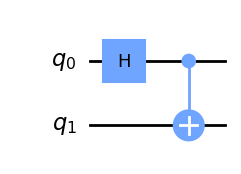

Possible measurement results and probabilities:
{np.str_('00'): 0.5, np.str_('11'): 0.5}
You get 00 or 11, not 01 or 10, when both qubits are measured in this basis.


In [38]:
# 🔵 LIVE — A genuine Qiskit Bell-pair circuit
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0,1)
display(bell.draw(output='mpl',style={'backgroundcolor':'#ffffff'}))
bell_sv = Statevector.from_instruction(bell)
print('Possible measurement results and probabilities:')
print({bits:round(float(p),3) for bits,p in bell_sv.probabilities_dict().items()
       if p>1e-10})
print('You get 00 or 11, not 01 or 10, when both qubits are measured in this basis.')


---

## 🟠 OPTIONAL — Shor's Algorithm: Building an RSA Factoring Circuit

### 🔐 The challenge: Can a quantum computer factor a number?

RSA encryption relies on the difficulty of factoring very large numbers.

For this demonstration, we use a small example:

$$N = 187$$

Our task is to discover two prime numbers whose product is **187**.

Instead of directly searching for factors, Shor's algorithm uses a quantum computer to discover a repeating mathematical pattern.

### Step 1 — Find a repeating pattern

We select a base:

$$a = 21$$

Then investigate:

$$f(x) = 21^x \bmod 187$$

The important quantity is the **period** — the number of steps after which the modular sequence repeats.

### Step 2 — Prepare the quantum circuit

Our educational circuit uses **5 qubits**:

| Qubits | Purpose |
|---|---|
| q0, q1, q2 | Quantum counting and phase estimation |
| q3, q4 | Compressed modular-operation register |

The circuit performs:

1. **Hadamard gates** — Prepare superposition.
2. **Controlled modular operations** — Encode the repeating pattern.
3. **Inverse Quantum Fourier Transform** — Extract phase information.

**🎯 Your challenge:** Examine the circuit. Can you predict what measurement results might reveal the repeating pattern?

> **Important:** This is a small, compiled quantum circuit specifically designed for 187 and base 21. It illustrates genuine quantum phase-estimation operations, but it is not a general-purpose implementation capable of factoring arbitrary RSA keys.

---


RSA SHOR — QUANTUM PERIOD-FINDING CIRCUIT
Number to factor: 187
Selected base: 21
Total qubits: 5


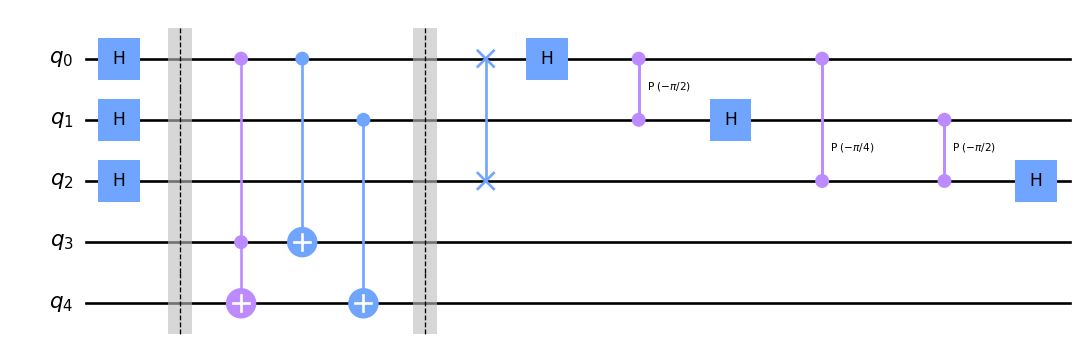


Circuit prepared. Run the next section
to measure the quantum phases and recover factors.


In [45]:

# 🟠 OPTIONAL — RSA Shor Circuit: Preparation and Visualization
# Compatible with Qiskit 0.45.1

from math import pi, gcd
from fractions import Fraction
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from IPython.display import display, HTML
import matplotlib.pyplot as plt

# STEP 1 — Select the factoring problem

shor_demo_N = 187
shor_demo_base = 21

# Reference modular sequence (not the final factorization)
sequence_187 = [
    pow(shor_demo_base, i, shor_demo_N)
    for i in range(5)
]

# STEP 2 — Create the 5-qubit circuit

period_qc = QuantumCircuit(5, name="RSA Shor Demo")

# q0, q1, q2: phase-estimation counting qubits
# q3, q4: compressed modular-operation register

# STEP 3 — Prepare quantum superposition

for q in range(3):
    period_qc.h(q)

period_qc.barrier()

# STEP 4 — Controlled modular operations
# The four members of the modular orbit are encoded
# as |00>, |01>, |10>, |11> on q4,q3.
#
# q0 controls U^1: increment the orbit index by 1
# q1 controls U^2: increment the orbit index by 2
# q2 controls U^4: identity in this compiled example

period_qc.ccx(0, 3, 4)
period_qc.cx(0, 3)
period_qc.cx(1, 4)

period_qc.barrier()

# STEP 5 — Inverse Quantum Fourier Transform
# Explicit gates, so students can see the circuit.
# No QFTGate import required.

period_qc.swap(0, 2)

for j in range(3):
    for m in range(j):
        angle = -pi / (2 ** (j - m))
        period_qc.cp(angle, m, j)
    period_qc.h(j)

# STEP 6 — Display quantum circuit

print("RSA SHOR — QUANTUM PERIOD-FINDING CIRCUIT")
print(f"Number to factor: {shor_demo_N}")
print(f"Selected base: {shor_demo_base}")
print(f"Total qubits: {period_qc.num_qubits}")

try:
    fig = period_qc.draw(
        output="mpl",
        style={"backgroundcolor": "#ffffff"},
        fold=-1,
        scale=0.95
    )
    display(fig)
    plt.close(fig)

except ImportError:
    print(period_qc.draw(output="text"))

print("\nCircuit prepared. Run the next section")
print("to measure the quantum phases and recover factors.")



---

## 🟠 OPTIONAL — Shor's Algorithm: Discover the Period and Factors

### Step 3 — Measure the quantum circuit

Our circuit has already prepared a quantum state containing information about the repeating modular function.

Now we will measure the **three counting qubits**.

Because we use three counting qubits, there are:

$$2^3 = 8$$

possible measurement results, numbered from **0 to 7**.

Every execution may return a different answer.

### Step 4 — Convert the measurement into a candidate period

If the measured result is \(m\), we estimate the phase:

$$\phi = \frac{m}{8}$$

We express the fraction in its simplest form. Its denominator gives us a **candidate period**.

We must then verify whether it really is a period:

$$21^r \bmod 187 = 1$$

If the measurement does not give a valid period, we repeat the experiment.

### Step 5 — Recover the factors

Once a suitable even period \(r\) is found, we calculate:

$$x = 21^{r/2} \bmod 187$$

Then:

$$p = \gcd(x-1,187)$$

$$q = \gcd(x+1,187)$$

If both are nontrivial factors and their product is 187, the factorization succeeds.

### 🎯 Your challenge

Run the next cell several times.

Observe:

- How many circuit measurements were needed?
- Which measurement values produced a useful period?
- Did every execution require the same number of attempts?
- What factors did the classical post-processing recover?

> **Key lesson:** The quantum part extracts information about periodicity. Classical mathematics verifies the candidate period and calculates the factors. In this educational circuit, the four-state modular orbit is compiled into the circuit in advance.

---


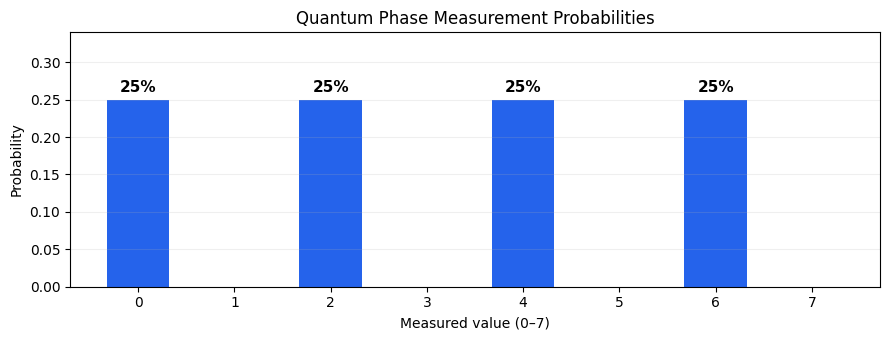

Quantum phase peaks: {0: 0.25, 2: 0.25, 4: 0.25, 6: 0.25}

SHOR'S ALGORITHM — QUANTUM EXPERIMENT
Run 01 | Measured 100 (4) | Phase 1/2 | Candidate 2 | Retry
Run 02 | Measured 000 (0) | Phase 0 | Candidate 1 | Retry
Run 03 | Measured 010 (2) | Phase 1/4 | Period 4 | SUCCESS



QUANTUM CIRCUIT STATISTICS
Qubits: 5
Gate instances per circuit: 13
Circuit depth: 9
Measurements attempted: 3
Gate instances across simulated runs: 39

NOTE:
This is an ideal, compiled 5-qubit demonstration.
Circuit depth is NOT a physical clock-cycle count.
It does not represent RSA-2048 cracking time.


In [46]:

# 🟠 OPTIONAL — RSA Shor: Measure, Find Period, Recover Factors
# Run the circuit-preparation cell first.

# STEP 1 — Simulate the prepared quantum circuit

period_state = Statevector.from_instruction(period_qc)

# Only measure the three counting qubits
phase_prob = period_state.probabilities_dict(
    qargs=[0, 1, 2]
)

phase_distribution = {
    int(bits, 2): float(probability)
    for bits, probability in phase_prob.items()
}

phase_peaks = {
    value: round(probability, 4)
    for value, probability in phase_distribution.items()
    if probability > 0.001
}

# STEP 2 — Visualize possible measurement results

fig, ax = plt.subplots(figsize=(9, 3.5))

xs = list(range(8))
ys = [phase_distribution.get(x, 0.0) for x in xs]

bars = ax.bar(
    xs, ys,
    color="#2563eb",
    width=0.65
)

for bar, probability in zip(bars, ys):
    if probability > 0.001:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            probability + 0.01,
            f"{probability * 100:.0f}%",
            ha="center",
            fontsize=11,
            fontweight="bold"
        )

ax.set_xticks(xs)
ax.set_ylim(0, 0.34)
ax.set_xlabel("Measured value (0–7)")
ax.set_ylabel("Probability")
ax.set_title("Quantum Phase Measurement Probabilities")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print("Quantum phase peaks:", phase_peaks)


# STEP 3 — Classical verification and factor recovery

def recover_factors(candidate_r):

    # A useful period for this factoring step must be even
    if candidate_r < 2 or candidate_r % 2 != 0:
        return None

    # Verify the measured candidate is a real period
    if pow(shor_demo_base, candidate_r, shor_demo_N) != 1:
        return None

    # Calculate a^(r/2) mod N
    x = pow(
        shor_demo_base,
        candidate_r // 2,
        shor_demo_N
    )

    # Reject trivial cases
    if x == 1 or x == shor_demo_N - 1:
        return None

    # Recover factors with GCD
    p = gcd(x - 1, shor_demo_N)
    q = gcd(x + 1, shor_demo_N)

    if 1 < p < shor_demo_N and 1 < q < shor_demo_N:
        if p * q == shor_demo_N:
            return tuple(sorted((p, q)))

    return None


# STEP 4 — Calculate probability of successful recovery

success_probability = sum(
    probability
    for measured, probability in phase_distribution.items()
    if recover_factors(
        Fraction(measured, 8).denominator
    ) is not None
)

expected_runs = (
    1 / success_probability
    if success_probability > 0 else float("inf")
)


# STEP 5 — Repeat measurement until successful

# ✏️ YOUR TURN — Change the maximum attempts
max_circuit_runs = 30

recovered_period = None
recovered_factors = None
run_count = 0

print("\n" + "=" * 52)
print("SHOR'S ALGORITHM — QUANTUM EXPERIMENT")
print("=" * 52)

for run_count in range(1, max_circuit_runs + 1):

    # Fresh sample from the same unmeasured circuit state
    measured_bits, _ = period_state.measure(
        qargs=[0, 1, 2]
    )

    measured_value = int(measured_bits, 2)

    # Convert phase to its lowest-term fraction
    phase_fraction = Fraction(measured_value, 8)

    # Denominator supplies the candidate period
    candidate_r = phase_fraction.denominator

    factors = recover_factors(candidate_r)

    if factors is not None:

        recovered_period = candidate_r
        recovered_factors = factors

        print(
            f"Run {run_count:02d} | "
            f"Measured {measured_bits} ({measured_value}) | "
            f"Phase {phase_fraction} | "
            f"Period {candidate_r} | SUCCESS"
        )

        break

    print(
        f"Run {run_count:02d} | "
        f"Measured {measured_bits} ({measured_value}) | "
        f"Phase {phase_fraction} | "
        f"Candidate {candidate_r} | Retry"
    )


# STEP 6 — Preserve results for future cells

r = recovered_period
quantum_circuit_runs = run_count

gate_count = sum(
    count
    for name, count in period_qc.count_ops().items()
    if name not in ("barrier", "measure")
)

circuit_depth = period_qc.depth()


# STEP 7 — Beautiful result dashboard

if recovered_factors is not None:

    p, q = recovered_factors

    display(HTML(f"""
    <div style="
      background:#0c2342;
      color:white;
      padding:25px;
      border-radius:15px;
      font-family:Arial,sans-serif;
      text-align:center;">

      <h2 style="color:#93c5fd;margin-top:0;">
        SHOR'S ALGORITHM — FACTORIZATION SUCCESS
      </h2>

      <div style="color:#cbd5e1;">
        Number to factor: {shor_demo_N}
      </div>

      <div style="
        font-size:40px;
        font-weight:bold;
        color:#34d399;
        margin:15px 0;">
        {p} × {q} = {shor_demo_N}
      </div>

      <div style="
        display:flex;
        gap:12px;
        flex-wrap:wrap;">

        <div style="
          flex:1;
          min-width:110px;
          padding:15px;
          border-radius:10px;
          background:#19345e;">

          <div style="font-size:30px;color:#facc15;">
            {recovered_period}
          </div>
          Period recovered
        </div>

        <div style="
          flex:1;
          min-width:110px;
          padding:15px;
          border-radius:10px;
          background:#19345e;">

          <div style="font-size:30px;color:#facc15;">
            {run_count}
          </div>
          Circuit samples
        </div>

        <div style="
          flex:1;
          min-width:110px;
          padding:15px;
          border-radius:10px;
          background:#19345e;">

          <div style="font-size:30px;color:#facc15;">
            {success_probability * 100:.0f}%
          </div>
          Success per sample
        </div>

      </div>

      <p style="color:#cbd5e1;margin-bottom:0;">
        Average expected samples: {expected_runs:.1f}
      </p>
    </div>
    """))

else:
    print("\nNo successful result in the allowed attempts.")
    print("Increase max_circuit_runs and run again.")


# STEP 8 — Report circuit complexity

print("\nQUANTUM CIRCUIT STATISTICS")
print("Qubits:", period_qc.num_qubits)
print("Gate instances per circuit:", gate_count)
print("Circuit depth:", circuit_depth)
print("Measurements attempted:", run_count)
print("Gate instances across simulated runs:",
      gate_count * run_count)

print("\nNOTE:")
print("This is an ideal, compiled 5-qubit demonstration.")
print("Circuit depth is NOT a physical clock-cycle count.")
print("It does not represent RSA-2048 cracking time.")


---

## 🔵 LIVE · Step 15 — Back to BSB: Eve saved a Diffie–Hellman handshake

Remember Part 1? Eve recorded the **public DH values** and the **AES-encrypted Dubai replication packet**, but could not feasibly recover a properly sized private DH secret using known practical classical methods.

**Shor's algorithm** matters because it has quantum methods for problems including **integer factorization** (RSA) and **discrete logarithms** (DH/ECDH). For the banking story, we need **discrete logarithms**, not RSA factorization.

**Now upload** the `bsb_dubai_capture.json` you downloaded from Part 1. The file has only the public handshake and ciphertext—no private keys.

> The live demonstration below models **quantum Fourier sampling with classical NumPy**. This is an educational simulation, not a full fault-tolerant quantum circuit or real quantum hardware attack.


In [32]:
# LIVE — Upload the public capture exported from Notebook 1
# This does NOT import Manama's private DH exponent, PSK or AES key.
if colab_files is not None:
    print('Select bsb_dubai_capture.json downloaded from Notebook 1')
    uploaded=colab_files.upload()
    if not uploaded:raise ValueError('No file selected')
    raw=json.loads(next(iter(uploaded.values())).decode('utf-8'))
else:
    with open('bsb_dubai_capture.json',encoding='utf-8') as f: raw=json.load(f)
byte_fields={'ni','nr','spi_i','spi_r','nonce','ciphertext'}
eve_capture={k:(bytes.fromhex(v) if k in byte_fields else v) for k,v in raw.items()}
for k in ['p','g','manama_pub','dr_pub','destination',*byte_fields]:
    assert k in eve_capture,f'Missing captured field: {k}'
show_metrics('Eve’s captured IPsec-style data', [('Public DH · Manama',eve_capture['manama_pub']),('Public DH · Dubai',eve_capture['dr_pub']),('Encrypted bytes',len(eve_capture['ciphertext']))], 'Only public handshake values and ciphertext were imported.')

---

## 🔵 LIVE · Step 16 — Prepare the discrete-logarithm sampling problem

Our toy example uses a tiny DH prime (`467`). From the public generator and Manama's public value, the simulator prepares the modular relationship needed to search for Manama's exponent.

**What is public?** `p`, `g`, Manama's DH public value and Dubai's public value. **What stays hidden?** The private exponent.

This cell **prepares** the small mathematical model. The following cell performs repeated simulated samples and checks the results.


BSB — SHOR'S DISCRETE LOGARITHM CIRCUIT
Prime modulus: 467
Generator: 2
Manama public DH: 312
Dubai public DH: 5

QUANTUM CIRCUIT ARCHITECTURE


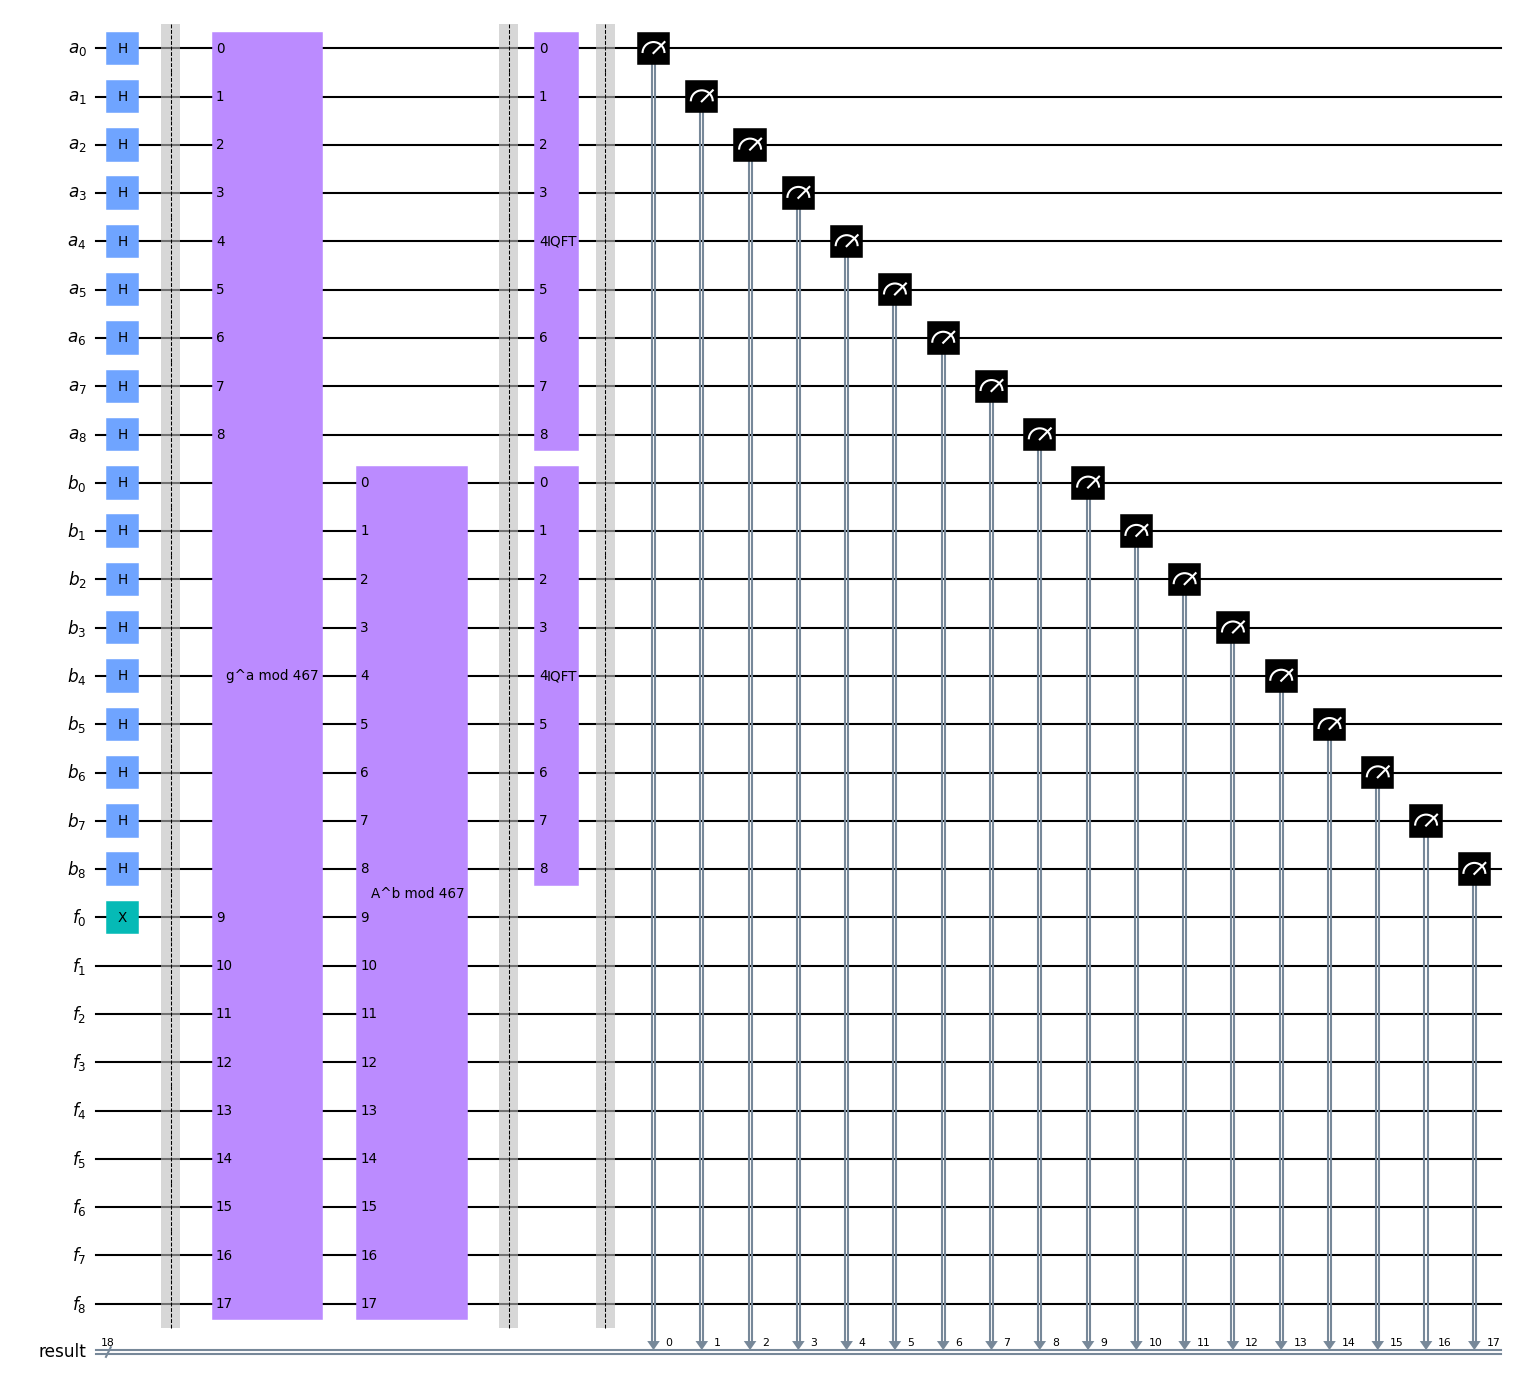


CIRCUIT DETAILS
Qubits in diagram: 27
Exponent-register width: 9
Classical measurement bits: 18

NOTE:
MOD_G and MOD_A represent unimplemented
reversible modular-arithmetic blocks.
This circuit is a visual architecture only.
The following Fourier-sampling cell performs
the actual classical mathematical simulation.


In [43]:

# 🔵 LIVE — BSB: Shor's Discrete Logarithm Circuit
# Compatible with Qiskit 0.45.1
# CIRCUIT ARCHITECTURE VISUALIZATION — not an executable Shor attack

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit import Gate
from qiskit.circuit.library import QFT
from IPython.display import display
import matplotlib.pyplot as plt

# STEP 1 — Public information captured by Eve

shor_dh_p = eve_capture['p']
shor_dh_g = eve_capture['g']
shor_dh_A = eve_capture['manama_pub']
shor_dh_B = eve_capture['dr_pub']

n_bits = (shor_dh_p - 1).bit_length()

print("BSB — SHOR'S DISCRETE LOGARITHM CIRCUIT")
print("Prime modulus:", shor_dh_p)
print("Generator:", shor_dh_g)
print("Manama public DH:", shor_dh_A)
print("Dubai public DH:", shor_dh_B)

# STEP 2 — Create quantum registers

reg_a = QuantumRegister(n_bits, "a")
reg_b = QuantumRegister(n_bits, "b")
reg_f = QuantumRegister(n_bits, "f")

reg_c = ClassicalRegister(2 * n_bits, "result")

shor_dh_qc = QuantumCircuit(
    reg_a, reg_b, reg_f, reg_c
)

# STEP 3 — Prepare superposition

for qubit in list(reg_a) + list(reg_b):
    shor_dh_qc.h(qubit)

# Function register starts at |1>
shor_dh_qc.x(reg_f[0])

shor_dh_qc.barrier()

# STEP 4 — Modular arithmetic (architecture placeholders)
# Intended function: f(a,b) = g^a * A^b mod p

modular_g = Gate(
    name="MOD_G",
    num_qubits=2 * n_bits,
    params=[],
    label=f"g^a mod {shor_dh_p}"
)

modular_A = Gate(
    name="MOD_A",
    num_qubits=2 * n_bits,
    params=[],
    label=f"A^b mod {shor_dh_p}"
)

shor_dh_qc.append(
    modular_g, list(reg_a) + list(reg_f)
)

shor_dh_qc.append(
    modular_A, list(reg_b) + list(reg_f)
)

shor_dh_qc.barrier()

# STEP 5 — Inverse Quantum Fourier Transform
# QFT class supported by Qiskit 0.45.1

inverse_qft = QFT(
    n_bits,
    do_swaps=True
).inverse().to_gate(label="IQFT")

shor_dh_qc.append(inverse_qft, list(reg_a))
shor_dh_qc.append(inverse_qft, list(reg_b))

shor_dh_qc.barrier()

# STEP 6 — Measure counting registers

shor_dh_qc.measure(
    list(reg_a) + list(reg_b),
    list(reg_c)
)

# STEP 7 — Display circuit

print("\nQUANTUM CIRCUIT ARCHITECTURE")

try:
    fig = shor_dh_qc.draw(
        output="mpl",
        style={"backgroundcolor": "#ffffff"},
        fold=30,
        scale=0.75
    )
    display(fig)
    plt.close(fig)

except Exception as err:
    print("Matplotlib drawing unavailable:", err)
    print(shor_dh_qc.draw(output="text", fold=100))

print("\nCIRCUIT DETAILS")
print("Qubits in diagram:", shor_dh_qc.num_qubits)
print("Exponent-register width:", n_bits)
print("Classical measurement bits:", shor_dh_qc.num_clbits)

print("\nNOTE:")
print("MOD_G and MOD_A represent unimplemented")
print("reversible modular-arithmetic blocks.")
print("This circuit is a visual architecture only.")
print("The following Fourier-sampling cell performs")
print("the actual classical mathematical simulation.")


In [47]:
# LIVE — Prepare the modular function from PUBLIC values only
shor_dh_p=eve_capture['p'];shor_dh_g=eve_capture['g']
shor_dh_A=eve_capture['manama_pub'];shor_dh_B=eve_capture['dr_pub']
assert shor_dh_p==467 and shor_dh_g==2,'This small Fourier example is compiled for p=467, g=2'
order=shor_dh_p-1
# The small group generator g=2 has full order 466 (verified independently).
assert pow(shor_dh_g,order,shor_dh_p)==1
assert all(pow(shor_dh_g,order//d,shor_dh_p)!=1 for d in [2,233])
g_values=np.array([pow(shor_dh_g,a,shor_dh_p) for a in range(order)],dtype=np.int64)
A_values=np.array([pow(shor_dh_A,b,shor_dh_p) for b in range(order)],dtype=np.int64)
f_values=(g_values[:,None]*A_values[None,:])%shor_dh_p
print('Quantum Fourier sampling model prepared from the captured DH exchange.')

Quantum Fourier sampling model prepared from the captured DH exchange.


---

## 🔵 LIVE · Step 17 — Try quantum-style Fourier samples

Run the sampler. Each attempt simulates a **Fourier measurement** and tests whether it reveals the correct private exponent. Some outcomes are useful, others are not; the program reports the number of attempts.

**✏️ Your turn:** increase `max_quantum_samples` or rerun to see the variation.

> **Important:** “Fourier samples” are **not** real quantum-gate cycles. A practical quantum machine would need many modular arithmetic gates, error correction and physical runtime.


In [48]:
# LIVE — Sample the Fourier spectrum; no access to bank private keys
# YOUR TURN — Change the sample limit and run again.
max_quantum_samples=25
rng=np.random.default_rng()
recovered_private=None
for run_count in range(1,max_quantum_samples+1):
    observed=int(g_values[rng.integers(order)])
    psi=(f_values==observed).astype(complex)
    psi/=np.linalg.norm(psi)
    amplitudes=np.fft.fft2(psi,norm='ortho')
    sample_probs=np.abs(amplitudes.ravel())**2
    sample_probs/=sample_probs.sum()
    u,v=divmod(int(rng.choice(order*order,p=sample_probs)),order)
    if gcd(u,order)==1:
        candidate=(v*pow(u,-1,order))%order
        if pow(shor_dh_g,candidate,shor_dh_p)==shor_dh_A:
            recovered_private=candidate
            break
if recovered_private is None:
    print('No successful sample yet. Increase max_quantum_samples and run again.')
else:
    quantum_circuit_runs=run_count # Historical name; THESE ARE SIMULATED FOURIER SAMPLES
    recovered_shared=pow(shor_dh_B,recovered_private,shor_dh_p)
    show_metrics('Shor-style discrete-logarithm recovery', [('Fourier samples',run_count),('Recovered exponent',recovered_private),('Recovered DH secret',recovered_shared)], 'Fourier samples are not physical quantum circuit runs or cycles.')

---

## 🔵 LIVE · Step 18 — Eve opens the recorded banking packet

This is the payoff of the BSB story. Eve uses the recovered DH exponent to reconstruct the **shared secret**. She then follows the **same key-derivation process** as the bank and decrypts the captured AES-GCM packet.

**Look for the banking record** you entered in Part 1. If you left the default unchanged, it will be `49218`.

This demonstration is deliberately small. It illustrates *why a future quantum discrete-logarithm attack threatens conventional DH/ECDH*, not a quantum break of a real deployed VPN today.


In [35]:
# LIVE — Derive recorded traffic key using recovered_shared
assert recovered_private is not None,'Run Section 10b until a sample recovers the exponent.'
def prf_plus(key,seed,size):
    out,previous,counter=b'',b'',1
    while len(out)<size:
        previous=hmac.new(key,previous+seed+bytes([counter]),sha256).digest()
        out+=previous
        counter+=1
    return out[:size]
def derive_data_key(shared_secret,ni,nr,spi_i,spi_r):
    shared_bytes=shared_secret.to_bytes(2,'big')
    skeyseed=hmac.new(ni+nr,shared_bytes,sha256).digest()
    sk_d=prf_plus(skeyseed,ni+nr+spi_i+spi_r,32*7)[:32]
    return prf_plus(sk_d,ni+nr,64)[:32]
eve_key=derive_data_key(recovered_shared,eve_capture['ni'],eve_capture['nr'],eve_capture['spi_i'],eve_capture['spi_r'])
recovered_message=AESGCM(eve_key).decrypt(eve_capture['nonce'],eve_capture['ciphertext'],eve_capture['destination'].encode()).decode()
show_metrics('BSB · archived banking data recovered',[('Recorded ciphertext',eve_capture['ciphertext'][:-16].hex()),('Recovered bank data',recovered_message)], 'Attack path: captured DH public values → simulated Fourier sampling → derived DH secret → AES-GCM decryption.')


---

## 🔵 LIVE — RSA vs Diffie–Hellman: Classical vs Quantum Computing

### 🔐 Can a quantum computer break today's encryption?

In our Bahrain Sample Bank (BSB) demonstration, Eve captured the encrypted banking traffic and the public Diffie–Hellman values exchanged between Manama and Dubai.

A classical attacker cannot practically recover the private exponent from a properly configured, modern DH group.

But what if Eve had access to a sufficiently powerful quantum computer?

**Shor's algorithm threatens two important public-key cryptographic problems:**

| Cryptographic system | Mathematical problem | Quantum attack |
|---|---|---|
| **RSA-2048** | Integer factorization | Shor's factoring algorithm |
| **DH-2048** | Finite-field discrete logarithm | Shor's discrete-logarithm algorithm |

Both provide approximately **112-bit classical security** under suitable parameter choices.

### 🧪 Experiment — Compare the computational requirements

We will compare two hypothetical classical computing systems with a future fault-tolerant quantum computer.

---


In [60]:

# 🔵 LIVE — RSA vs Diffie-Hellman: Classical and Quantum
# Gidney–Ekerå 2019/2021 research estimates
# Both quantum results use EXPECTED TIME TO SUCCESS.
#
# Requires show_metrics() from the notebook setup.

# =========================================================
# STEP 1 — CLASSICAL COMPUTING ASSUMPTIONS
# =========================================================

# ✏️ YOUR TURN — Change these hypothetical work rates

laptop_work_per_second = 10**9
supercomputer_work_per_second = 10**18

seconds_per_year = 365.25 * 24 * 3600

# Approximate classical security strengths
rsa_bits = 2048
rsa_security_bits = 112

dh_bits = 2048
dh_security_bits = 112


# =========================================================
# STEP 2 — QUANTUM RESEARCH PARAMETERS
# =========================================================

# RSA-2048 — Gidney–Ekerå, Table 3

physical_qubits = 20_000_000

rsa_per_run_hours = 5.1
rsa_retry_risk = 0.31

approx_toffoli_gates = 2_600_000_000


# DH-2048 — Modified Shor algorithm, Table 5
# Safe-prime group, full-length discrete logarithm

dh_physical_qubits = 26_000_000

dh_per_run_hours = 7.0
dh_retry_risk = 0.05


# =========================================================
# STEP 3 — CLASSICAL WORK-TIME ILLUSTRATION
# =========================================================

def illustrative_years(security_bits, work_per_second):
    """Illustrative 2^security_bits work units, not a
    measured cryptanalytic runtime."""
    return (
        (2 ** security_bits)
        / work_per_second
        / seconds_per_year
    )


rsa_laptop_years = illustrative_years(
    rsa_security_bits,
    laptop_work_per_second
)

rsa_supercomputer_years = illustrative_years(
    rsa_security_bits,
    supercomputer_work_per_second
)

dh_laptop_years = illustrative_years(
    dh_security_bits,
    laptop_work_per_second
)

dh_supercomputer_years = illustrative_years(
    dh_security_bits,
    supercomputer_work_per_second
)


# Preserve original notebook variables

laptop_billion_years = rsa_laptop_years / 1e9

classical_years = rsa_supercomputer_years
classical_billion_years = classical_years / 1e9


# =========================================================
# STEP 4 — QUANTUM EXPECTED TIME TO SUCCESS
# =========================================================

# Account for runs that need to be repeated.
# Assumes independent attempts with the stated retry risk.

def expected_quantum_hours(per_run_hours, retry_risk):
    if not (0 <= retry_risk < 1):
        raise ValueError("Retry risk must be between 0 and 1.")
    return per_run_hours / (1 - retry_risk)


rsa_expected_hours = expected_quantum_hours(
    rsa_per_run_hours,
    rsa_retry_risk
)

dh_expected_hours = expected_quantum_hours(
    dh_per_run_hours,
    dh_retry_risk
)

# Preserve these names for following notebook cells
quantum_hours = rsa_expected_hours
dh_quantum_hours = dh_expected_hours

rsa_expected_runs = 1 / (1 - rsa_retry_risk)
dh_expected_runs = 1 / (1 - dh_retry_risk)


# =========================================================
# STEP 5 — RSA-2048 DASHBOARD
# =========================================================

show_metrics(
    'RSA-2048 · Factoring with Shor',
    [
        (
            'Laptop · illustrative work',
            f'{rsa_laptop_years / 1e9:,.0f} BILLION YEARS'
        ),

        (
            'Exascale · illustrative work',
            f'{rsa_supercomputer_years / 1e6:,.0f} MILLION YEARS'
        ),

        (
            'Quantum · expected success',
            f'{rsa_expected_hours:.1f} HOURS'
        ),

        (
            'Quantum · research model',
            f'{physical_qubits:,} PHYSICAL QUBITS'
        )
    ],

    'Gidney–Ekerå 2019/2021, Table 3. '
    f'{rsa_per_run_hours:.1f} hours per run, '
    f'{rsa_retry_risk:.0%} retry risk; '
    f'approximately {rsa_expected_hours:.1f} hours '
    'expected to succeed. '
    'Hypothetical fault-tolerant quantum computer. '
    'Not a demonstrated attack. '
    'Classical figures use abstract equivalent-work assumptions.'
)


# =========================================================
# STEP 6 — DIFFIE–HELLMAN DASHBOARD
# =========================================================

show_metrics(
    'DH-2048 · Breaking BSB-style Key Exchange',
    [
        (
            'Laptop · illustrative work',
            f'{dh_laptop_years / 1e9:,.0f} BILLION YEARS'
        ),

        (
            'Exascale · illustrative work',
            f'{dh_supercomputer_years / 1e6:,.0f} MILLION YEARS'
        ),

        (
            'Quantum · expected success',
            f'{dh_expected_hours:.1f} HOURS'
        ),

        (
            'Quantum · research model',
            f'{dh_physical_qubits:,} PHYSICAL QUBITS'
        )
    ],

    'Gidney–Ekerå 2019/2021, Table 5. '
    'Modified Shor discrete-logarithm algorithm for '
    'a 2048-bit safe-prime finite-field DH group. '
    f'{dh_per_run_hours:.1f} hours per run, '
    f'{dh_retry_risk:.0%} retry risk; '
    f'approximately {dh_expected_hours:.1f} hours '
    'expected to succeed. '
    'Not a demonstrated attack. '
    'BSB classroom DH uses a much smaller prime, p=467.'
)


# =========================================================
# STEP 7 — DETAILED RESEARCH COMPARISON
# =========================================================

print('\n' + '=' * 58)
print('QUANTUM RESOURCE COMPARISON — 2019/2021 MODEL')
print('=' * 58)

print(f'{"Metric":<29} {"RSA-2048":>12} {"DH-2048":>12}')
print('-' * 58)

print(
    f'{"Physical qubits":<29}'
    f' {physical_qubits/1e6:>10.0f} M'
    f' {dh_physical_qubits/1e6:>10.0f} M'
)

print(
    f'{"Hours per run":<29}'
    f' {rsa_per_run_hours:>11.1f}'
    f' {dh_per_run_hours:>11.1f}'
)

print(
    f'{"Retry risk":<29}'
    f' {rsa_retry_risk:>11.0%}'
    f' {dh_retry_risk:>11.0%}'
)

print(
    f'{"Expected runs":<29}'
    f' {rsa_expected_runs:>11.2f}'
    f' {dh_expected_runs:>11.2f}'
)

print(
    f'{"Expected hours to success":<29}'
    f' {rsa_expected_hours:>11.2f}'
    f' {dh_expected_hours:>11.2f}'
)

print('\nRSA abstract gate estimate:')
print(f'~{approx_toffoli_gates:,} Toffoli operations.')

print('\nIMPORTANT:')
print('1. Classical times are illustrative, not benchmarks.')
print('2. Quantum runtimes include estimated retry overhead.')
print('3. RSA factoring and DH discrete log use different circuits.')
print('4. These quantum computers have not been demonstrated.')
print('5. Newer research may yield different resource estimates.')



QUANTUM RESOURCE COMPARISON — 2019/2021 MODEL
Metric                            RSA-2048      DH-2048
----------------------------------------------------------
Physical qubits                       20 M         26 M
Hours per run                         5.1         7.0
Retry risk                            31%          5%
Expected runs                        1.45        1.05
Expected hours to success            7.39        7.37

RSA abstract gate estimate:
~2,600,000,000 Toffoli operations.

IMPORTANT:
1. Classical times are illustrative, not benchmarks.
2. Quantum runtimes include estimated retry overhead.
3. RSA factoring and DH discrete log use different circuits.
4. These quantum computers have not been demonstrated.
5. Newer research may yield different resource estimates.
